# 11 — Audit of the real catalogs (Stage 1)

Stage 1 of `docs/real_data_roadmap.md`: read the EDD files exactly as published, read what
every column means, and check that units, ranges and counts are what we think they are — before
anything physical is computed. Sections 1–8 audit the original three files (CF4 groups, CF4
velocities, Tempel). Sections 9–12 are the **Stage 1 addendum** from the advisor meeting of
2026-10-14 (`docs/advisor_notes.md`): the 2MRS catalog Nusser used, the three catalogs on one sky,
and CF4 broken down by distance method.

**Thin consumer.** Every number and figure below comes from two library modules:
`dvcorr.pipeline.real_catalogs` (the EDD reader, the loaders, and the formulas EDD used to build
CF4's velocity columns) and `dvcorr.pipeline.real_catalog_audit` (the checks and figures). Their
docstrings are the definition site; this notebook only calls them and says what to look for.

Each section states **what is checked**, **why it matters**, and **how to verify it yourself** with
a one-liner on the raw table, so no number here has to be taken on trust. The last section puts
every measured number next to the roadmap's *Expect (measured)* list.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd

from dvcorr import conventions
from dvcorr.pipeline import real_catalog_audit as audit
from dvcorr.pipeline.real_catalogs import (
    Cf4VelocityDefinitions,
    column_descriptions,
    load_cf4_groups,
    load_cf4_velocities,
    load_tempel_galaxies,
    load_twomrs_galaxies,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

velocities = load_cf4_velocities()
groups = load_cf4_groups()
tempel = load_tempel_galaxies()
twomrs = load_twomrs_galaxies()
definitions = Cf4VelocityDefinitions()
config = audit.AuditConfig()

# The three catalogs reduced to directions and cz, densest first (drawn at the bottom of maps).
samples = [audit.tempel_sky_sample(tempel, config), audit.twomrs_sky_sample(twomrs), audit.cf4_sky_sample(groups)]

for catalog in (velocities, groups, tempel, twomrs):
    print(f"{catalog.path.name:28s} {catalog.title!r:32s} rows {len(catalog.table):>7,}  columns {catalog.table.shape[1]}")
print(definitions)

CF4_Groups_Velocities.csv    'CF4 All Group Velocities'       rows  38,057  columns 22
CF4_Groups.csv               'CF4 All Groups'                 rows  38,057  columns 30
SDSS_Tempel.csv              'Tempel17 SDSS DR12 Clipped'     rows 305,952  columns 21
2MRS_K<11.75.txt             '2MRS K<11.75'                   rows  43,526  columns 32
Cf4VelocityDefinitions(h0=74.6, q0=-0.595, j0=1.0, ramp_velocity=3000.0)


## 1 — The column dictionary

EDD files carry **five** header lines: title, names, printf formats, units, descriptions.
`read_edd_csv` keeps the names, turns the other three into a column dictionary
(`catalog.columns`), and refuses a file whose format line is not printf formats rather than
guessing. `column_range_table` puts each column's realized `min`/`max` and missing count beside its
unit and description: **the label is documentation, the range is evidence.**

*Verify yourself:* `head -5 data/CF4_Groups_Velocities.csv` shows the five lines; the format row
(`%6.3f`, `%5d`, …) also says how each value was rounded, which section 6 uses as the tolerance of
every reconstruction.

In [2]:
audit.column_range_table(velocities)

,unit,format,min,max,n_missing,description
column,,,,,,
pgc,---,%7s,12.0000,9.003288e+06,0,The Catalogue of Principal Galaxies (PGC) Number
DMzp,mag,%6.3f,20.3690,3.964900e+01,0,Distance modulus of group averaged over all contributions; Absolute scale set by calib...
eDM,mag,%5.3f,0.0000,1.910000e+00,0,Error assigned to distance modulus
D,Mpc,%5.1f,0.1000,8.507000e+02,0,Distance
Vhel,km/s,%5d,-331.0000,3.288500e+04,0,Heliocentric radial velocity
Vls,km/s,%5d,-157.0000,3.298400e+04,0,Radial velocity in Local Sheet reference frame (Tully et al. 2008)
Vcmb,km/s,%5d,-617.0000,3.257500e+04,0,Radial velocity in reference frame of cosmic microwave background
fV,km/s,%5d,-616.0000,3.530000e+04,0,Radial velocity in CMB frame with cosmic curvature adjustment
Vpds,km/s,%6d,-27617.0000,1.368200e+04,0,Peculiar velocity following Davis & Scrimgeour (2014)


In [3]:
audit.column_range_table(groups)

,unit,format,min,max,n_missing,description
column,,,,,,
pgc,---,%7s,12.0000,9.003288e+06,0,The Catalogue of Principal Galaxies (PGC) Number
DM_zp,mag,%6.3f,20.3690,3.964900e+01,0,"Group weighted average distance modulus (w=1/sigma^2) over 5 methods (FP,TF,SBF,SNIa,S..."
DM_av,mag,%6.3f,0.0000,3.978600e+01,0,"Group weighted average distance modulus (w=1/sigma^2) over 5 methods (FP,TF,SBF,SNIa,S..."
eDM_av,mag,%5.3f,0.0080,1.910000e+00,0,"Error of all measured moduli, excluding TRGB and Cepheid calibrators, derived from inv..."
Vcmb,km/s,%5d,-617.0000,3.257500e+04,0,"Group radial velocity in CMB frame, averaged over all galaxies in 2MASS K<11.75 group ..."
RA,hour,%8.4f,0.0023,3.599976e+02,0,Right ascension J2000 in decimal degrees
DE,deg,%8.4f,-89.3347,8.813660e+01,0,Declination J2000
GLong,deg,%8.4f,0.0333,3.599968e+02,0,Galactic longitude
GLat,deg,%8.4f,-89.4851,8.965420e+01,0,Galactic latitude


In [4]:
audit.column_range_table(tempel)

,unit,format,min,max,n_missing,description
column,,,,,,
pgc,---,%7s,20859.00000,6.773065e+06,0,The Catalogue of Principal Galaxies (PGC) Number
ID,,%6d,5.00000,5.844490e+05,0,ID in Tempel+14 galaxy catalog
IDg,,%5d,0.00000,8.866200e+04,0,Tempel+17 group ID
Ng,,%3d,1.00000,2.540000e+02,0,Number of galaxies in Tempel+14 group
Rg,,%3d,1.00000,2.540000e+02,0,Luminosity rank within group
dc,Mpc,%6.2f,0.65000,4.499500e+02,0,Co-moving distance to group assuming H0=67.8 km/s/Mpc
gVcmb,km/s,%5d,45.00000,3.093200e+04,0,Group velocity in CMB frame
zobs,,%7.5f,0.00000,1.001000e-01,0,Observed redshift of galaxy
zcmb,,%7.5f,0.00015,1.000000e-01,0,Redshift of galaxy in CMB frame


### Trap 3 — units lie

The roadmap's example is RA labelled `hour` with values reaching 359.998. That trap is in
**`CF4_Groups.csv`** (Tempel and the velocities file label RA correctly as `deg`). A second lie of
the same kind is in Tempel: `den3`/`den10` are labelled `Mpc^-3`, but their description says
*normalized* environmental density — dimensionless. Neither is used downstream yet; the lesson is
to read ranges, not labels.

*Verify yourself:* `groups.table.RA.max()` is 359.9976 — impossible for hours (< 24).

In [5]:
units = pd.concat(
    {
        "CF4_Groups": audit.column_range_table(groups).loc[["RA", "DE"]],
        "CF4_Groups_Velocities": audit.column_range_table(velocities).loc[["RA", "DE"]],
        "SDSS_Tempel": audit.column_range_table(tempel).loc[["RA", "DE", "den3", "den10"]],
    }
)
units[["unit", "min", "max", "description"]]

unit       min       max                                               description
                      column                                                                                      
CF4_Groups            RA        hour    0.0023  359.9976                  Right ascension J2000 in decimal degrees
                      DE         deg  -89.3347   88.1366                                         Declination J2000
CF4_Groups_Velocities RA         deg    0.0023  359.9976                           Right Ascension of group, J2000
                      DE         deg  -89.3347   88.1366                               Declination of group, J2000
SDSS_Tempel           RA         deg  109.7607  261.6594                                     Right ascension J2000
                      DE         deg   -3.7438   70.2665                                         Declination J2000
                      den3    Mpc^-3    0.0000  457.3400   Normalized environmental density, smoothing scale 3 Mpc
                      den10   Mpc^-3    0.0200   30.8600  Normalized environmental density, smoothing scale 10 Mpc

## 2 — The two CF4 files against each other

`CF4_Groups_Velocities.csv` (velocities) and `CF4_Groups.csv` (per-method distance moduli) describe
the same groups. `compare_cf4_files` joins them **on `pgc`** (one-to-one, so a repeated key would
raise) and lists every disagreement on a quantity both carry. Row order is checked separately:
the roadmap says the two join row by row, and the check is that this is *true*, not assumed.

*Verify yourself:* `(velocities.table.pgc.values == groups.table.pgc.values).all()`.

In [6]:
cf4 = audit.compare_cf4_files(velocities, groups, config)
print("rows:", cf4.n_velocities, cf4.n_groups, " joined on pgc:", cf4.n_joined, " same row order:", cf4.same_row_order)
print(f"Vcmb disagreements: {len(cf4.vcmb_mismatch)}   position disagreements (> {config.position_tolerance_deg} deg): {len(cf4.position_mismatch)}   eDM vs eDM_av: {len(cf4.edm_mismatch)}")
cf4.vcmb_mismatch

rows: 38057 38057  joined on pgc: 38057  same row order: True
Vcmb disagreements: 7   position disagreements (> 0.001 deg): 1   eDM vs eDM_av: 229


,pgc,Vcmb_velocities,Vcmb_groups,difference
6586,39940,4403,4407,-4
6851,42447,1173,1190,-17
6974,43296,3885,3690,195
6995,43423,4340,3690,650
8738,52984,11756,11823,-67
24763,2001449,7499,7504,-5
33780,3640534,9545,9550,-5


**Vcmb.** Seven groups have different `Vcmb` in the two files (up to 650 km/s for pgc 43423).
`fV` in the velocities file is built from the *velocities* file's `Vcmb` (section 6 reproduces it
in every row), so that file is internally consistent; which value is right for the group is not
decidable from these files. Seven of 38,057 — note and move on.

**Position.** One group, pgc 51922, sits 41° apart in the two files. Tempel has a galaxy with the same
`pgc`, which settles it:

In [7]:
display(cf4.position_mismatch)
t = tempel.table
t.loc[t.pgc.isin(cf4.position_mismatch.pgc), ["pgc", "RA", "DE", "zcmb", "IDg"]].assign(
    cz_cmb=lambda d: d.zcmb * conventions.SPEED_OF_LIGHT
)

,pgc,RA_velocities,DE_velocities,RA_groups,DE_groups,separation_deg
8491,51922,246.7607,22.2281,218.0237,57.9531,41.294024


,pgc,RA,DE,zcmb,IDg,cz_cmb
16644,51922,218.0238,57.9531,0.06362,12593,19072.796178


Tempel's pgc 51922 is at (218.0238, 57.9531) with cz = 19,073 km/s — the **groups** file's position,
to 1e-4°, and the CF4 `Vcmb` exactly. The velocities file's (246.76, 22.23) is wrong for this group
(its own galactic coordinates are self-consistent with the wrong RA/DE, so it is not a typo in one
column). **Consequence for Stage 2:** take CF4 positions from `CF4_Groups.csv`, or drop pgc 51922.

**eDM.** 229 rows differ between `eDM` (velocities) and `eDM_av` (groups). 228 of them are the
`eDM = 0` rows of roadmap item 5:

In [8]:
edm = cf4.edm_mismatch
zero = edm[edm.eDM == 0]
print(f"eDM = 0 rows: {len(zero)}   all with Nc >= 1 (Cepheid/TRGB calibrators): {bool((zero.Nc >= 1).all())}   "
      f"their eDM_av: {sorted(zero.eDM_av.unique())}   max D: {zero.D.max()} Mpc")
print("the other one:")
display(edm[edm.eDM != 0])
print("eDM_av description:", column_descriptions(groups)["eDM_av"])

eDM = 0 rows: 228   all with Nc >= 1 (Cepheid/TRGB calibrators): True   their eDM_av: [np.float64(0.1)]   max D: 109.1 Mpc
the other one:


,pgc,eDM,eDM_av,Nc,D
4278,27776,0.37,0.59,NaN,48.4


eDM_av description: Error of all measured moduli, excluding TRGB and Cepheid calibrators, derived from inverse of summed weight


So `eDM = 0` is not "an exact distance": these are the calibrator groups, and the groups-file
description says the measured-moduli error **excludes** TRGB and Cepheid calibrators — the error is
simply not given. `velocity_error_from_modulus_error` returns NaN for them, so they can never get
infinite inverse-variance weight; under Nusser's w = 1 they are harmless. One further group
(pgc 27776) has `eDM` 0.37 vs `eDM_av` 0.59 — a single-row disagreement, noted.

## 3 — Tempel is a galaxy table: Traps 1, 2 and 4

The EDD title is "Tempel17 SDSS DR12 **Clipped**": one row per galaxy (`ID` and `pgc` unique), each
row carrying its group's `IDg`, `Ng`, `Rg`, `dc`, `gVcmb`. `tempel_traps` counts every way a naive
"one row per group" reading breaks.

- **Trap 1:** `IDg = 0` is shared by *every* isolated galaxy. A naive `groupby("IDg")` merges them into
  one fake group (`naive_largest_group`). A singleton's identity is its galaxy `ID`.
- **Trap 2:** groups with no `Rg = 1` row (the clipped table dropped the brightest member), and groups
  with fewer rows than `Ng`. The descriptions explain why: `Ng` is "Number of galaxies in
  **Tempel+14** group" while `IDg` is "**Tempel+17** group ID" — `Ng` is a parent-catalog richness.
- **Trap 4:** `gVcmb` ("Group velocity in CMB frame") differs between members of the same group;
  `dc` ("co-moving distance to group") never does.

*Verify yourself:* `t[t.IDg > 0].groupby("IDg").Rg.min().ne(1).sum()` → 375.

In [9]:
traps = audit.tempel_traps(tempel)
for name, value in vars(traps).items():
    print(f"{name:28s} {value}")
print()
print(f"fraction of groups with fewer rows than Ng : {traps.groups_fewer_rows_than_ng / traps.n_groups:.4f}")
print(f"fraction of groups whose gVcmb varies      : {traps.groups_gvcmb_varies / traps.n_groups:.4f}")
descriptions = column_descriptions(tempel)
for column in ("ID", "IDg", "Ng", "Rg", "dc", "gVcmb"):
    print(f"{column:6s} {descriptions[column]}")

n_galaxies                   305952
id_unique                    True
pgc_unique                   True
n_isolated                   130010
isolated_ng_values           (1,)
isolated_rg_values           (1,)
naive_largest_group          130010
n_groups                     49671
n_group_rows                 175942
groups_without_brightest     375
groups_fewer_rows_than_ng    752
groups_more_rows_than_ng     0
groups_single_row            402
groups_ng_varies             0
groups_gvcmb_varies          9449
groups_dc_varies             0

fraction of groups with fewer rows than Ng : 0.0151
fraction of groups whose gVcmb varies      : 0.1902
ID     ID in Tempel+14 galaxy catalog
IDg    Tempel+17 group ID
Ng     Number of galaxies in Tempel+14 group
Rg     Luminosity rank within group
dc     Co-moving distance to group assuming H0=67.8 km/s/Mpc
gVcmb  Group velocity in CMB frame


Beyond the roadmap: **402 groups with `Ng ≥ 2` appear as a single row** (`groups_single_row`) —
after clipping they look like singletons but must keep their `IDg`. Stage 2's collapse handles them
correctly only if it keys on `IDg` for `IDg > 0`, never on row count.

The roadmap's Trap 4 example, `IDg = 1558`: `gVcmb` takes three values among the six brightest
members, while `dc` is constant. The members tagged 7,578 km/s have their own `cz_cmb` near 7,600, so
`gVcmb` behaves like a sub-group velocity, not one group velocity — use `dc` for the radius.

In [10]:
audit.group_members(tempel, config.example_group).head(10)

,Rg,ID,pgc,Ng,gVcmb,dc,cz_cmb
0,1,277214,45580,46,6503,102.47,6247.674825
1,2,308265,45406,46,6503,102.47,6520.485961
2,3,296878,45542,46,6503,102.47,6760.319928
3,4,443923,94031,46,7578,102.47,7695.672397
4,5,492206,45386,46,6441,102.47,6538.473509
5,6,501322,94029,46,6503,102.47,6283.649920
6,7,462711,45442,46,7578,102.47,7560.765791
7,8,484525,94033,46,7064,102.47,6970.174648
8,9,513424,83781,46,6503,102.47,6448.535772
9,10,515315,3084927,46,6490,102.47,6445.537847


## 4 — Sky coverage

Mollweide maps in equatorial coordinates, RA increasing to the **left** (sky convention), RA = 0 at
the center. **What right looks like:** CF4 all-sky with a band empty along the Galactic plane (the
Zone of Avoidance, an S-shaped band in equatorial coordinates); Tempel one contiguous northern patch
— the SDSS Legacy north cap, RA ≈ 110°–262°, DE ≈ −4° to 70°. Extra patches (e.g. the SDSS southern
stripes) would mean the sample is not what we think. *Observed:* one contiguous cap; the thin strip
along DE ≈ 0 near RA 236°–250° is the SDSS equatorial stripe, attached to the cap's southern edge, not
a separate region. CF4 is densest inside the same SDSS area (its Fundamental-Plane sample).

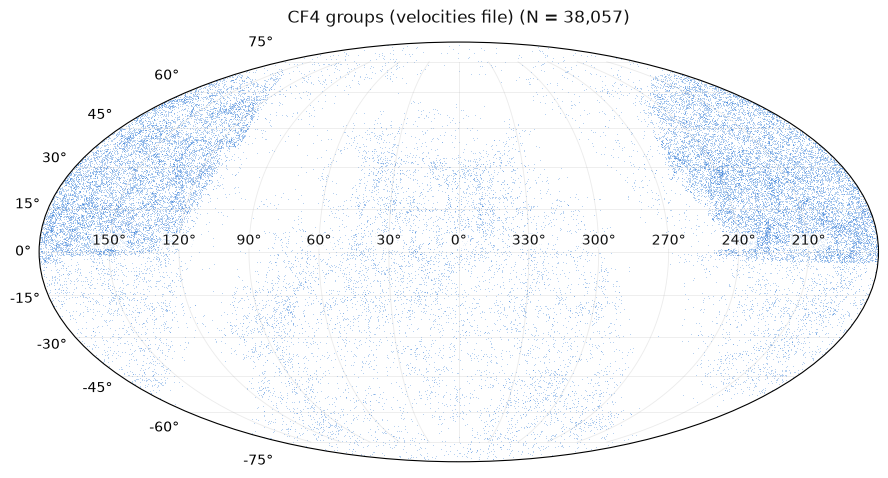

In [11]:
fig = audit.make_sky_map(velocities.table.RA, velocities.table.DE, title="CF4 groups (velocities file)")

Tempel RA range 109.76 – 261.66 deg, DE range -3.74 – 70.27 deg


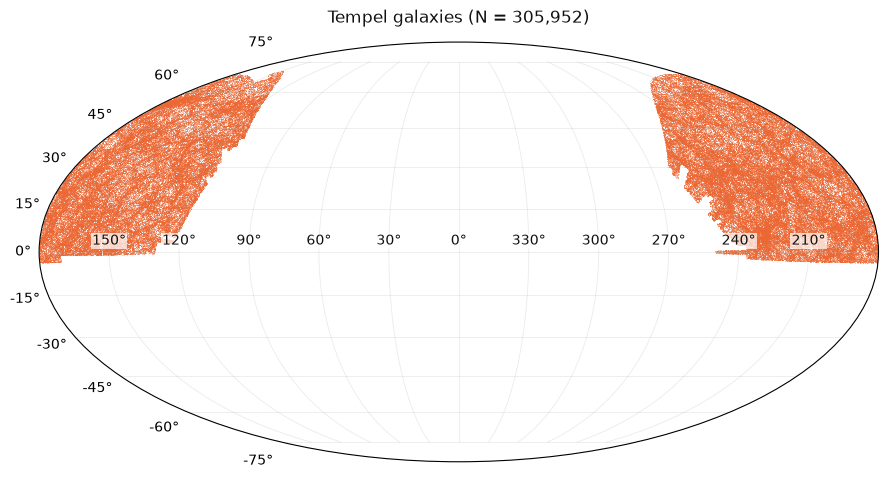

In [12]:
fig = audit.make_sky_map(tempel.table.RA, tempel.table.DE, title="Tempel galaxies", color="#eb6834")
print(f"Tempel RA range {tempel.table.RA.min():.2f} – {tempel.table.RA.max():.2f} deg, DE range {tempel.table.DE.min():.2f} – {tempel.table.DE.max():.2f} deg")

**Footprint area.** Counting occupied HEALPix pixels overestimates with coarse pixels (an edge pixel
counts whole) and underestimates with fine ones (sparse interior pixels come out empty), so the
answer is a range, not one number. The roadmap's ≈ 7,600 deg² is the nside = 32 value; Stage 4's
footprint (nside 64) gives ≈ 7,400. SDSS Legacy's north cap is ~7,500 deg², inside the range.

In [13]:
audit.footprint_area_table(tempel.table.RA, tempel.table.DE, config)

,pixel_area_deg2,occupied_pixels,area_deg2
nside,,,
32,3.357175,2270,7620.786299
64,0.839294,8810,7394.177014
128,0.209823,34344,7206.175238


**2MRS (addendum).** The density field Nusser used. **What right looks like:** the whole sky except
a band along the Galactic plane. In equatorial coordinates that band is the same S-shaped Zone of
Avoidance as CF4's, but with a **sharp** edge at |b| = 5° (8° toward the bulge, near RA ≈ 266°,
δ ≈ −29°), because 2MRS was cut there by design (section 9 checks that no galaxy crosses it).
Large-scale structure should be visible: the Virgo cluster near RA 187°, δ 12°, the Perseus–Pisces
chain near RA 20–60°, δ 30–40°, and Centaurus/Hydra in the south near RA 160–200°, δ −30 to −45°.

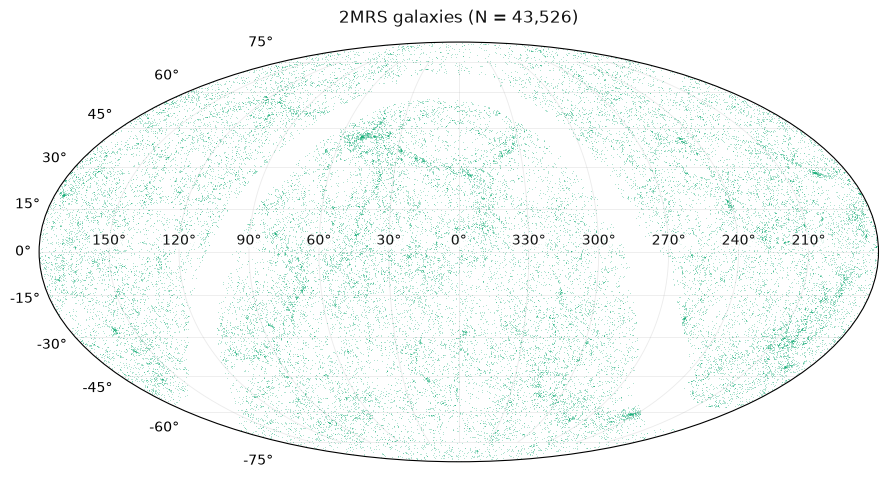

In [14]:
fig = audit.make_sky_map(twomrs.table.RAJ, twomrs.table.DEJ, title="2MRS galaxies", color="#1baf7a")

**2MRS area.** 2MRS is defined by a mask, not by where its galaxies happen to fall, so its area is the
mask area, counted on fine HEALPix pixel centers (`twomrs_mask_area`). For comparison, the
occupied-pixel method that worked for Tempel (section 4 above) fails here: at ~1 galaxy per deg²,
even 3.4 deg² pixels come out empty in voids, so every resolution *under*-counts, and finer pixels
do worse.

*Verify yourself:* the area with |b| < b₀ is 4π·sin b₀ steradians, so the mask keeps
41,253·[1 − sin 5° − (60/360)(sin 8° − sin 5°)] ≈ 37,300 deg², 90.4% of the sky.

In [15]:
mask_area = audit.twomrs_mask_area(config)
print(f"2MRS mask area: {mask_area:,.0f} deg^2 ({mask_area / (4 * np.pi * np.rad2deg(1.0) ** 2):.1%} of the sky)")
audit.footprint_area_table(twomrs.table.RAJ, twomrs.table.DEJ, config)

2MRS mask area: 37,323 deg^2 (90.5% of the sky)


,pixel_area_deg2,occupied_pixels,area_deg2
nside,,,
32,3.357175,9959,33434.101651
64,0.839294,22471,18859.767502
128,0.209823,32571,6834.158330


## 5 — Redshift distributions

`n(cz)` in 1,000 km/s bins, each catalog in its own panel (they differ several-fold in size; the
question is shape). **What right looks like:** Tempel galaxies rising to a broad peak around
20,000–25,000 km/s and cut sharply at z = 0.1 (the dashed line, ≈ 29,980 km/s); CF4 with a nearby
population (mostly Tully–Fisher) plus the SDSS Fundamental-Plane population peaking near 24,000
and ending at ~30,000; 2MRS (added in the addendum) a flux-limited survey peaking at 5,000–10,000 —
median 8,401 km/s, Huchra et al.'s z ≈ 0.028 — with a thin tail past 30,000.

**Frames:** Tempel and CF4 are CMB-frame; 2MRS carries only a *heliocentric* velocity. The two
differ by up to ~370 km/s (the CMB dipole), invisible at this bin width. The conversion is Stage 3's
job.

Tempel zcmb max: 0.1   CF4 Vcmb range: -617 – 32575


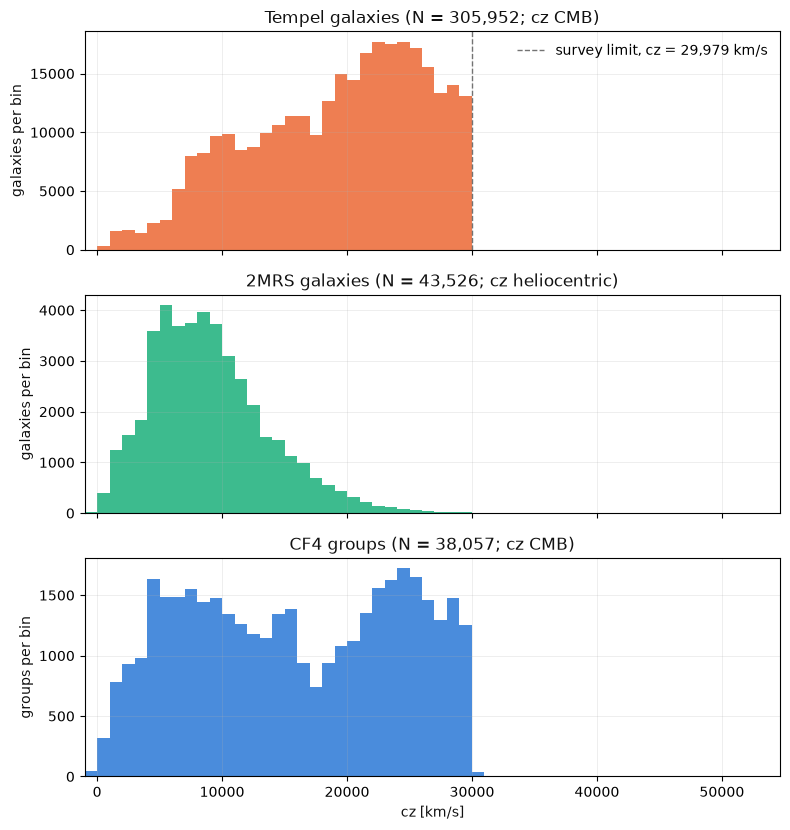

In [16]:
fig = audit.make_cz_histogram_figure(samples, config)
print("Tempel zcmb max:", tempel.table.zcmb.max(), "  CF4 Vcmb range:", velocities.table.Vcmb.min(), "–", velocities.table.Vcmb.max())

## 6 — Rebuilding CF4's velocity columns

The velocities file carries inputs (`Vcmb`, `Vls`, `DMzp`) and derived columns (`D`, `fV`, `Vpds`,
`Vpwf`, `Vpec`). `reconstruct_cf4_velocities` rebuilds each derived column **only from the columns it
is derived from** — so a residual blames exactly one formula — and judges it against the file's own
rounding: every input and the output are perturbed by half their last printed digit (from the
format row), and a row counts as reproduced when `|published − rebuilt|` stays within that envelope.
Constants: c = 299,792.458 km/s, H0 = 74.6 (`CosmologyConfig.H0_CF4`), D = 10^((DMzp−25)/5) Mpc.

*Verify yourself (first row, pgc 12):* `fV = 6280`, `D = 99.3` →
`(6280 − 74.6·99.3)/(1 + 74.6·99.3/c) = −1127.8/1.0247 = −1100.6` vs published `Vpds = −1098`
— the 2.6 km/s gap is `D`'s own rounding (`%5.1f`): with D = 10^((34.984−25)/5) = 99.266 Mpc it is
−1098.1. Likewise `6280/(1 + 6280/c) · log10(6280/(74.6·99.266)) = −440.3` vs published `Vpwf = −440`.

In [17]:
reconstruction = audit.reconstruct_cf4_velocities(velocities, definitions)
reconstruction.summary

,formula,n_compared,rms_residual,max_abs_residual,n_outside_rounding,fraction_within_rounding
column,,,,,,
D,10^((DMzp - 25)/5),38057,0.028517,0.050075,0,1.000000
fV,Vcmb[1 + (1-q0)z/2 - (1-q0-3q0^2+j0)z^2/6],38057,0.289557,0.888465,0,1.000000
Vpds,(fV - H0 D)/(1 + H0 D/c),38057,1.266126,225.200438,98,0.997425
Vpwf,fV/(1 + fV/c) log10(fV/(H0 D)),38008,0.648073,106.453288,70,0.998158
Vpec,"w Vpds + (1-w) Vpwf, w = clip(1 - Vls/ramp, 0, 1); w = 1 if fV < 0",38057,0.088692,0.967667,0,1.000000


All five formulas hold. `D`, `fV` and `Vpec` are reproduced in **every** row. `Vpds` and `Vpwf` miss
the envelope in 98 and 70 rows, but almost all by only ~1 km/s (EDD evidently rounded intermediate
values slightly differently than the envelope assumes); the rows missing by more than 5 km/s are
listed below — five individual rows, not a pattern.

Three things the formulas say that the roadmap did not:

1. **`Vpds = (fV − H0·D)/(1 + H0·D/c)`, not `fV − 74.6·D`.** The denominator is Davis & Scrimgeour's
   1/(1 + z_h); without it residuals reach thousands of km/s at large D.
2. **`Vpwf` uses log₁₀ where Watkins & Feldman use ln.** The published column is ln 10 = 2.303 times
   smaller than the peculiar velocity it estimates (section 7).
3. **`Vpec` is a ramp:** `w·Vpds + (1−w)·Vpwf`, `w = clip(1 − Vls/3000, 0, 1)` in the *Local-Sheet*
   velocity — pure `Vpds` at Vls = 0, pure `Vpwf` from Vls = 3,000 km/s on (94% of rows, which is why
   `Vpec = Vpwf` for 94%). Where fV ≤ 0 (45 rows below zero, 4 at zero; log undefined) EDD writes a **filler
   `Vpwf = 0`**; below zero it takes `Vpec = Vpds`, at fV = 0 exactly it blends with the filler. Those zeros are fills, not
   velocities (hard rule 5): any use of `Vpwf` as a variant (Stage 12) must drop fV ≤ 0, as
   `watkins_feldman_velocity` does by returning NaN.

In [18]:
r = reconstruction.residuals
excess = {c: (r[f"{c}_residual"].abs() - r[f"{c}_envelope"]) for c in ("Vpds", "Vpwf")}
worst = velocities.table.loc[(excess["Vpds"] > 5) | (excess["Vpwf"] > 5),
                             ["pgc", "DMzp", "D", "Vls", "Vcmb", "fV", "Vpds", "Vpwf", "Vpec"]]
worst.assign(Vpds_residual=r.Vpds_residual.round(1), Vpwf_residual=r.Vpwf_residual.round(1))

,pgc,DMzp,D,Vls,Vcmb,fV,Vpds,Vpwf,Vpec,Vpds_residual,Vpwf_residual
5956,36319,34.590,82.8,6020,6498,6610,650,297,297,225.2,106.5
6421,38890,32.542,32.2,2068,2500,2517,52,23,32,-59.0,-26.3
6547,39659,32.243,28.1,2259,2570,2588,496,239,302,7.2,3.9


## 7 — The σ_u puzzle

**The puzzle (roadmap item 4).** The naive noise σ_u = (ln 10/5)·eDM·cz *exceeds* the total measured
`Vpec` scatter by 2–2.5× at every depth. Noise cannot exceed signal plus noise.

**The answer.** `Vpec` (beyond Vls = 3,000) *is* `Vpwf`, and `Vpwf` is computed with log₁₀: it is the
peculiar velocity divided by ln 10 = 2.303 — the factor in the puzzle. `eDM` is a correct error
for the velocity on the natural-log scale. Two independent tests:

**Test 1 — scale, no error model needed.** Where |v| ≪ cz, ln(1+x) ≈ x, so the Watkins–Feldman
and Davis–Scrimgeour estimators must *agree* to first order: they are two forms of one velocity.
`linear_regime_ratio` takes the median of `Vpwf/Vpds` over rows with 200 < |Vpds| < 0.1·fV.
1 means `Vpwf` estimates v; 1/ln 10 = 0.434 means it carries log₁₀. The control rebuilds `Vpwf`
with ln.

*Verify yourself:* `(velocities.table.Vpwf / velocities.table.Vpds).median()` over all rows is ~0.43.

rows in linear regime            : 12,603
median Vpwf(published) / Vpds    : 0.4371   (1/ln10 = 0.4343)
median Vpwf(rebuilt, ln) / Vpds  : 1.0065   (control; should be 1)


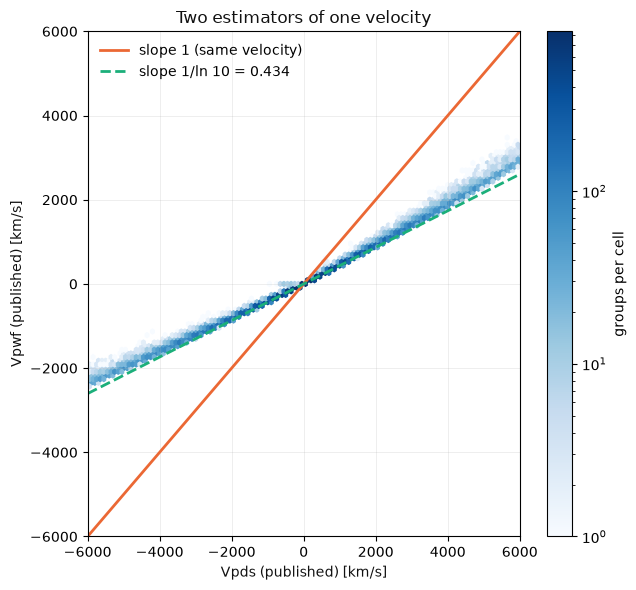

In [19]:
ratio = audit.linear_regime_ratio(velocities, definitions, config)
print(f"rows in linear regime            : {ratio.n_rows:,}")
print(f"median Vpwf(published) / Vpds    : {ratio.median_published_ratio:.4f}   (1/ln10 = {1/np.log(10):.4f})")
print(f"median Vpwf(rebuilt, ln) / Vpds  : {ratio.median_natural_log_ratio:.4f}   (control; should be 1)")
fig = audit.make_velocity_definition_figure(velocities, config)

The data lie on the slope-1/ln 10 line, not slope 1. In the figure the cloud follows the dashed line
near the origin. At large |Vpds| the cloud bends *above* that line on both sides: with
y = H0·D/fV, ln(1/y) ≥ 1 − y for every y, so the log form is larger for positive and smaller in
magnitude for negative velocities than the linear one — the asymmetry that makes WF's error Gaussian
in the modulus while `Vpds`'s is skewed.

**Test 2 — noise budget.** `velocity_noise_by_depth` compares, per cz bin, the rms σ_u predicted by
`eDM` for the ln-scale velocity, σ_u = (ln 10/5)·eDM·fV/(1+fV/c), with the observed scatter of three
columns. Because eDM varies from group to group, the fair statistic is per-object:
**std(v/σ_u)**. It should be ≥ 1 (noise plus signal), and ≈ 1 where noise dominates.

In [20]:
noise = audit.velocity_noise_by_depth(velocities, definitions, config)
noise.round(3)

,cz_lo,cz_hi,cz_median,n,n_calibrators,vpec_median,sigma_u_rms,naive_sigma_u_mean,std_vpec_published,std_vpwf_ln,std_vpds,zstd_vpec_published,zstd_vpwf_ln,zstd_vpds,implied_signal_rms
0,0.0,5000.0,3384.5,4454,190,-19.0,719.064,646.620,363.980,760.016,781.352,1.624,1.775,2.111,246.112
1,5000.0,10000.0,7434.0,7436,1,-2.5,1586.754,1503.285,669.295,1541.100,1590.491,0.427,0.983,0.995,-377.890
2,10000.0,15000.0,12429.0,6277,0,16.0,2906.654,2785.407,1175.343,2706.329,2808.364,0.418,0.963,0.972,-1060.386
3,15000.0,20000.0,17280.5,5092,0,26.5,3857.732,3793.905,1604.280,3693.979,3833.465,0.421,0.970,0.988,-1112.031
4,20000.0,25000.0,22811.0,7377,0,-49.0,5032.146,5026.266,2044.656,4707.991,4847.974,0.410,0.944,0.960,-1776.883
5,25000.0,35000.0,27388.0,7185,0,-76.0,6214.282,6274.942,2426.991,5588.367,5727.594,0.393,0.906,0.918,-2717.988


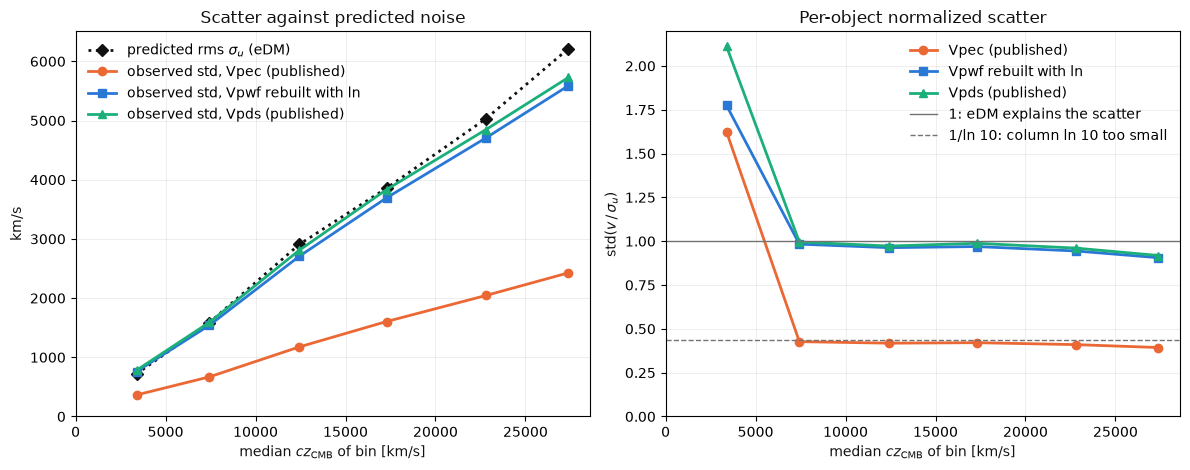

In [21]:
fig = audit.make_noise_comparison_figure(noise)

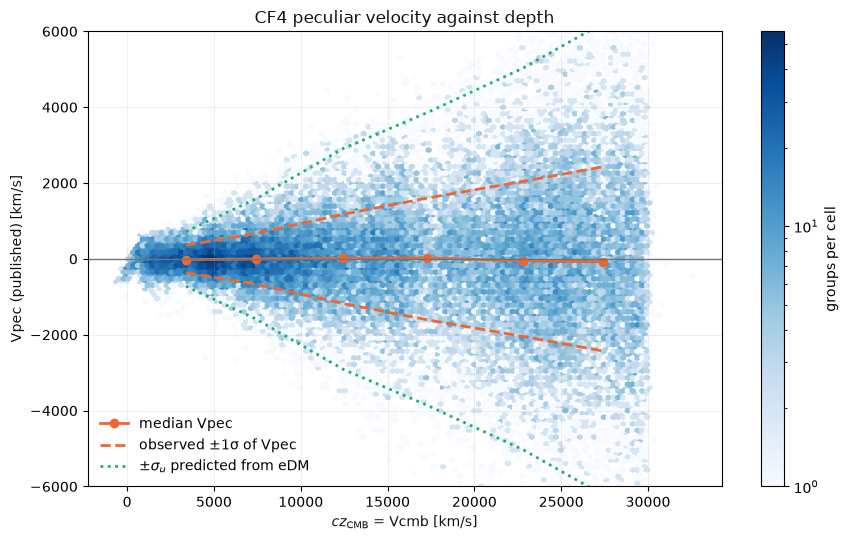

In [22]:
fig = audit.make_vpec_vs_cz_figure(velocities, noise, config)

**Reading the table and figures.**

- Published `Vpec`: std(v/σ_u) = 0.39–0.43 beyond 5,000 km/s — the 1/ln 10 line. That *is* the
  puzzle: the published column is 2.3× too narrow for its own errors.
- `Vpwf` rebuilt with ln: std(v/σ_u) = 0.98, 0.96, 0.97, 0.94, 0.91 from 5k to 35k. eDM explains
  the scatter; the column is noise-dominated beyond ~5,000 km/s, as expected for 20%-ish distance
  errors. The slight dip below 1 at depth (and the negative `implied_signal_rms`) says eDM is a few
  per cent *conservative* there — not a contradiction.
- `Vpds` has the same width as the ln form (it estimates the same v), with heavier, asymmetric tails
  at large distance (std/σ_u ≈ 1.0, but values down to −27,600 km/s): the non-Gaussian errors WF exists
  to avoid.
- Below 5,000 km/s, std(v/σ_u) = 1.8 and `implied_signal_rms` ≈ 250 km/s: there the cosmic signal is
  visible above the noise, which is where the dipole's information lives (Nusser's cz < 10,000).

**Consequences — for your decision, not changed in code:**

1. Using the published `Vpec` as u would scale the measured dipole, and the inferred fσ₈, **down by
   ≈ 2.3** for every object beyond Vls = 3,000, and by a cz-dependent mix inside the ramp. The
   velocity signal should be rebuilt with ln — e.g. `Vpec_ln = w·Vpds + (1−w)·watkins_feldman_velocity(fV, D)`
   — or the published `Vpwf` multiplied by ln 10. Which, and whether to keep EDD's ramp, is a
   Stage 2 decision.
2. σ_u for the Stage 8 bootstrap is `velocity_error_from_modulus_error(eDM, fV)` on the ln scale,
   with calibrators (eDM = 0) handled explicitly.
3. Not verified here: what Tully et al. (2023) print for the CF4 velocity formula (the paper is not
   in `literature/`). The two tests above stand on the file alone; checking the paper (or asking
   EDD) would say whether this is a known convention or an error in the table.

## 8 — Measured against the roadmap's *Expect (measured)*

Every number of Stage 1 next to the roadmap's value, with a verdict written by hand per row (an
automatic string comparison would call 1.51% vs "1.5%" a disagreement).

In [23]:
v = velocities.table
cz_bins = [(0, 5000), (5000, 10000), (10000, 15000), (15000, 20000), (20000, 40000)]
medians = [int(np.median(v.Vpec[(v.Vcmb >= lo) & (v.Vcmb < hi)])) for lo, hi in cz_bins]
row_5_10k = noise.set_index("cz_lo").loc[5000.0]
pds_resid = reconstruction.summary.loc["Vpds"]
A = "agrees"
rows = [
    ("CF4 groups", 38057, len(v), A, ""),
    ("CF4 velocities NaNs", 0, int(v.isna().sum().sum()), A, "CF4_Groups.csv has NaNs, in per-method columns only"),
    ("Vcmb min", -617, int(v.Vcmb.min()), A, ""),
    ("Vcmb max", 32575, int(v.Vcmb.max()), A, ""),
    ("CF4 files same pgc order", True, cf4.same_row_order, "agrees, with exceptions", "but 7 Vcmb, 1 position (41 deg), 229 eDM disagree"),
    ("Tempel rows", 305952, traps.n_galaxies, A, ""),
    ("Tempel ID, pgc unique", True, traps.id_unique and traps.pgc_unique, A, ""),
    ("footprint area deg2", "≈7600", str(audit.footprint_area_table(t.RA, t.DE, config).area_deg2.round().astype(int).to_dict()), "agrees at nside 32", "resolution-dependent"),
    ("Trap 1: IDg = 0 rows", 130010, traps.n_isolated, A, ""),
    ("Trap 2: groups without Rg = 1", 375, traps.groups_without_brightest, A, ""),
    ("Trap 2: fraction rows < Ng", "1.5%", f"{traps.groups_fewer_rows_than_ng / traps.n_groups:.2%}", A, f"{traps.groups_fewer_rows_than_ng} groups"),
    ("Trap 3: RA labelled hour, max", 359.998, float(groups.table.RA.max()), A, "it is CF4_Groups.csv, not Tempel"),
    ("Trap 4: gVcmb varies in groups", "19%", f"{traps.groups_gvcmb_varies / traps.n_groups:.1%}", A, f"{traps.groups_gvcmb_varies:,} groups"),
    ("Trap 4: dc varies in groups", 0, traps.groups_dc_varies, A, ""),
    ("Vpds = fV - 74.6 D exactly", "holds", "(fV - 74.6 D)/(1 + 74.6 D/c)", "DIFFERS", "the denominator is missing in the roadmap"),
    ("median Vcmb / D (D > 20 Mpc)", 71.5, round(float(np.median((v.Vcmb / v.D)[v.D > 20])), 2), A, ""),
    ("median Vpec per depth", [-13, -2, 16, 27, -64], medians, "agrees to ±1", "medians of an integer column"),
    ("naive sigma_u at 5-10k (mean)", 1466, round(row_5_10k.naive_sigma_u_mean), "differs by 2.5%", "same formula; averaging evidently differs"),
    ("observed Vpec std at 5-10k", 670, round(row_5_10k.std_vpec_published), A, ""),
    ("eDM = 0 groups", 228, int((v.eDM == 0).sum()), A, "all calibrators (Nc >= 1)"),
    ("eDM = 0 max D (Mpc)", "< 110", float(v.D[v.eDM == 0].max()), A, ""),
    ("Vpec == Vpwf fraction", "94%", f"{(v.Vpec == v.Vpwf).mean():.1%}", A, ""),
    ("Vpec != Vpwf rows", 2125, int((v.Vpec != v.Vpwf).sum()), A, ""),
]
comparison = pd.DataFrame(rows, columns=["item", "roadmap", "measured", "verdict", "note"])
comparison

,item,roadmap,measured,verdict,note
0,CF4 groups,38057,38057,agrees,
1,CF4 velocities NaNs,0,0,agrees,"CF4_Groups.csv has NaNs, in per-method columns only"
2,Vcmb min,-617,-617,agrees,
3,Vcmb max,32575,32575,agrees,
4,CF4 files same pgc order,True,True,"agrees, with exceptions","but 7 Vcmb, 1 position (41 deg), 229 eDM disagree"
5,Tempel rows,305952,305952,agrees,
6,"Tempel ID, pgc unique",True,True,agrees,
7,footprint area deg2,≈7600,"{32: 7621, 64: 7394, 128: 7206}",agrees at nside 32,resolution-dependent
8,Trap 1: IDg = 0 rows,130010,130010,agrees,
9,Trap 2: groups without Rg = 1,375,375,agrees,


**Where the roadmap is wrong or incomplete** (everything else agrees):

- `Vpds = fV − 74.6·D` does **not** hold exactly; the published formula is
  `(fV − 74.6·D)/(1 + 74.6·D/c)`. 74.6 itself is confirmed.
- Trap 3 is in `CF4_Groups.csv`; Tempel's RA is correctly labelled. Tempel's `den3`/`den10` carry a
  wrong unit instead.
- "The two CF4 files join row by row" is true of `pgc`, but they disagree on 7 `Vcmb`, 1 position
  (pgc 51922, velocities file wrong) and 229 `eDM` (228 calibrators + 1).
- The footprint "≈ 7,600 deg²" is resolution-dependent (7,206–7,621 for nside 128–32).
- Medians and the 5–10k noise numbers agree to rounding; the naive-σ_u mean is 1,503 vs 1,466 —
  the formula is the same, the roadmap's averaging evidently slightly different. Immaterial: the
  puzzle is a factor 2.3, not 3%.

**σ_u puzzle — resolved:** the published `Vpwf` (and `Vpec` beyond Vls = 3,000) is computed with
log₁₀ and is ln 10 too small; eDM is a correct (slightly conservative) error for the ln-scale velocity.

## 9 — Addendum: the 2MRS catalog

`2MRS_K<11.75.txt` is the 2MASS Redshift Survey (Huchra et al. 2012) as EDD publishes it — the
density field of Nusser (2017), who quotes "∼45,000 galaxies with K_s ≤ 11.75" and a mask at
|b| ≤ 5° (8° toward the bulge). Despite the `.txt` it is an EDD CSV with the same five-line header,
so `read_edd_csv` reads it unchanged. One row per galaxy.

**Ranges against labels** (the section 1 discipline): the table below has no missing values, but
it does have **sentinel fillers**: `J_c` = 99.999 and `e_J` = 9.999 (40 rows each), `b/a` = 9.999
(1 row), `e_V` = 999 (2 rows). They are 9-filled "no value" markers, not measurements. None of these
columns is used downstream (we need positions, `K_tc` and `Vhel`), but no statistic should be taken
of them unfiltered.

In [24]:
audit.column_range_table(twomrs)

,unit,format,min,max,n_missing,description
column,,,,,,
pgc,---,%7s,1.00000,5.061296e+06,0,The Catalogue of Principal Galaxies (PGC) Number
ID_2MASXJ,,%20s,NaN,NaN,0,2MASS Extended Source Catalog identification
RAJ,deg,%9.5f,0.00354,3.599950e+02,0,"Right ascension J2000, decimal degrees"
DEJ,deg,%9.5f,-89.33452,8.909319e+01,0,"Declination J2000, decimal degrees"
Glon,deg,%9.5f,0.00013,3.599966e+02,0,Galactic longitude
Glat,deg,%9.5f,-89.73062,8.996177e+01,0,Galactic latitude
SGL,deg,%9.5f,0.00510,3.599775e+02,0,Supergalactic longitude
SGB,deg,%9.5f,-89.03876,8.874212e+01,0,Supergalactic latitude
K_c,mag,%6.3f,0.79700,1.175400e+01,0,"Ks isophotal magnitude, extinction corrected"


**Against its survey definition.** `twomrs_checks` tests the file against what 2MRS is supposed to
be:

- the selection is on the **total** extinction-corrected magnitude `K_tc` ≤ 11.75. The isophotal
  `K_c` exceeds 11.75 in 200 rows, which is allowed: it is not the selection magnitude.
- every galaxy must lie inside the latitude mask `in_twomrs_footprint` (|b| ≥ 5°, and ≥ 8° for
  l < 30° or l > 330°).
- 23 non-positive heliocentric velocities are expected, not errors: M31 and its satellites, M33,
  M81, and Virgo galaxies falling toward us (M86, M90, NGC 4419…).

*Verify yourself:* `twomrs.table.query("Glat.abs() < 8 and (Glon < 30 or Glon > 330)")` is empty,
and `twomrs.table.Glat.abs().min()` is 5.001.

In [25]:
checks = audit.twomrs_checks(twomrs)
for name, value in vars(checks).items():
    print(f"{name:28s} {value}")
print()
print(f"Huchra et al. (2012) quote 43,533 galaxies; this file has {checks.n_galaxies:,} ({checks.n_galaxies - 43_533:+d}).")

n_galaxies                   43526
pgc_unique                   True
id_unique                    True
n_missing                    0
max_total_magnitude          11.75
n_isophotal_beyond_limit     200
n_outside_mask               0
n_nonpositive_vhel           23
n_velocity_error_not_given   787
median_vhel                  8401.0

Huchra et al. (2012) quote 43,533 galaxies; this file has 43,526 (-7).


**Cross-match by `pgc`.** Both Tempel and CF4 carry PGC numbers, so the same galaxy can be compared
across catalogs with no positional matching. Heliocentric velocity is compared with heliocentric
velocity, so no frame conversion enters: 2MRS `Vhel` against Tempel's c·`zobs`, and against CF4's
`Vhel`. The CF4 value is the **group** velocity, keyed by the group's `pgc`, so a spread there is the
group velocity dispersion, not a disagreement.

In [26]:
audit.twomrs_crossmatch(twomrs, tempel, velocities, config).round(1)

,n_matched,median_dv,robust_sigma_dv,n_beyond_tolerance
partner,,,,
Tempel galaxies (c zobs),8848,-0.4,1.5,172
CF4 groups (group Vhel),9701,0.0,5.9,1686


**Reading it.** For the 8,848 galaxies in both 2MRS and Tempel, the median difference is −0.4 km/s
and the robust scatter is 1.5 km/s: the same spectra, or the same literature redshifts. 172 differ by
more than 100 km/s (11 by more than 1,000), which are catastrophic-redshift cases in one survey or
the other. That is 2% of matches, noted and left alone. Against CF4 the scatter is wider, and 1,686
matches differ by more than 100 km/s, which is the group dispersion expected when one galaxy is
compared with its group's mean.

A by-product: of the 9,538 2MRS galaxies inside the SDSS footprint (next section), 8,848 are in
Tempel. **690 bright 2MRS galaxies inside the footprint are missing from Tempel**, most likely the
SDSS spectroscopic bright limit and fiber collisions. Stage 4's selection function has to know
that Tempel loses its brightest galaxies.

## 10 — The three catalogs on one sky

The density tracers are Tempel (SDSS) and 2MRS. The velocity tracer is CF4. The estimator needs
both ends of each pair, so what matters is where they overlap. Each map draws Tempel first (at the
bottom), then 2MRS, then CF4 on top. The guides are the Galactic plane (solid) and the 2MRS mask
edge at |b| = 5° (dashed). The bulge widening to 8° is not drawn. In equatorial coordinates the
plane is the arch through RA ≈ 100° and 280°, reaching δ = +63° at RA 13° and −63° at RA 193°,
which is why it hooks along the bottom edge.

**What to look for:** Tempel is the one northern cap. 2MRS and CF4 cover everything outside the
Zone of Avoidance. CF4 is densest inside the SDSS cap (the SDSS FP sample) and in the south (6dFGS
FP).

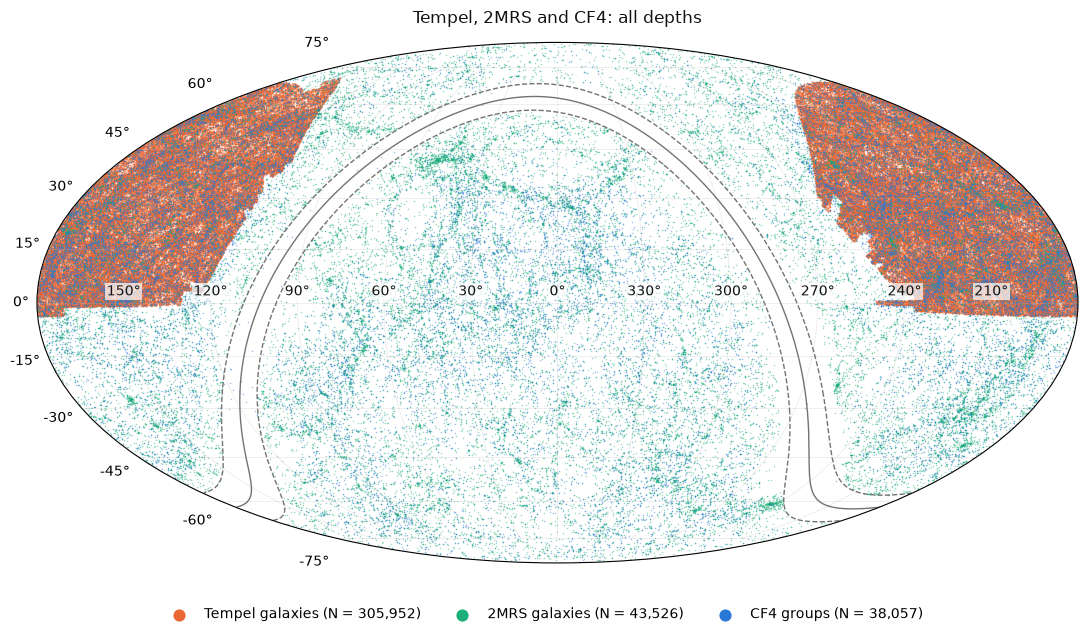

In [27]:
fig = audit.make_overlap_sky_map(samples, title="Tempel, 2MRS and CF4: all depths")

At all depths, Tempel's 306k galaxies fill the cap so densely that the other two hardly show there.
The analysis uses only cz < 10,000 km/s (Nusser's cut, `config.analysis_cz_max`), so the second map
cuts every catalog at that depth, each in its own frame. Inside the cap the large-scale structure
now shows (the Coma–A1367 filament near RA 180–195°, δ ≈ 20–30°), and the CF4 points visibly sit
on the same filaments as the density tracers.

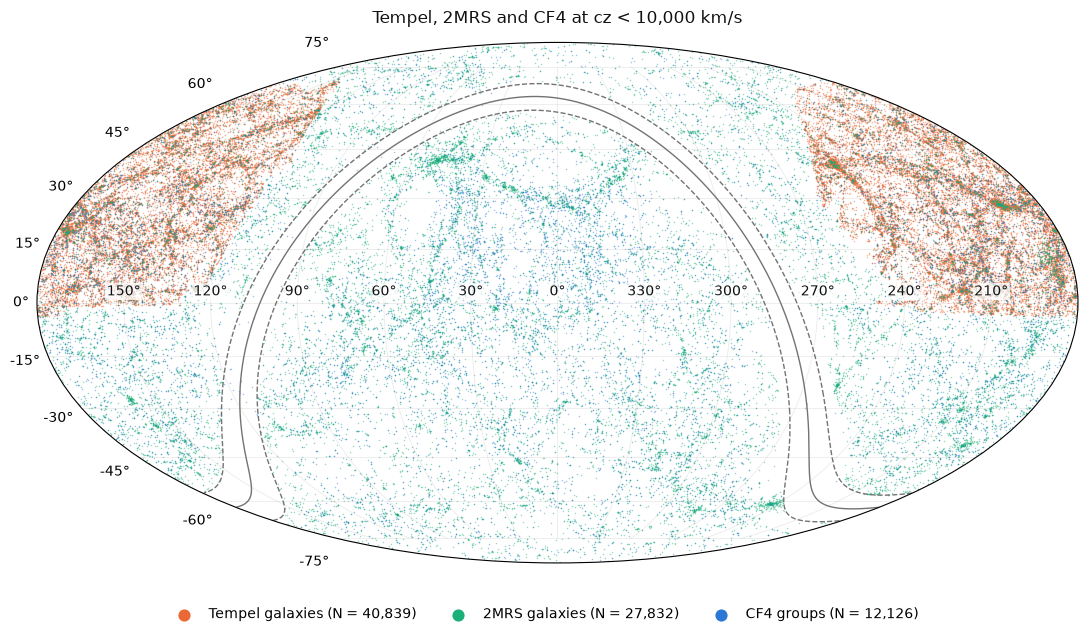

In [28]:
fig = audit.make_overlap_sky_map(samples, title="Tempel, 2MRS and CF4 at cz < 10,000 km/s",
                                 cz_max=config.analysis_cz_max)

**Overlap in numbers.** `sky_overlap_table` counts each catalog inside the SDSS footprint (HEALPix
pixels at nside 32 that hold a Tempel galaxy; slightly generous at the edges, see section 4) and
inside the 2MRS mask. These are the counts for all depths and for cz < 10,000 km/s:

In [29]:
pixels = audit.sdss_footprint_pixels(tempel, config)
overlap = pd.concat(
    {
        "all depths": audit.sky_overlap_table(samples, pixels, config),
        "cz < 10,000": audit.sky_overlap_table(samples, pixels, config, cz_max=config.analysis_cz_max),
    }
)
overlap.round(3)

n  in_sdss  in_twomrs_mask  in_both  frac_sdss  frac_twomrs_mask  frac_both
            catalog                                                                                          
all depths  Tempel galaxies  305952   305952          305952   305952      1.000             1.000      1.000
            2MRS galaxies     43526     9538           43526     9538      0.219             1.000      0.219
            CF4 groups        38057    26303           38007    26303      0.691             0.999      0.691
cz < 10,000 Tempel galaxies   40839    40839           40839    40839      1.000             1.000      1.000
            2MRS galaxies     27832     6303           27832     6303      0.226             1.000      0.226
            CF4 groups        12126     4481           12077     4481      0.370             0.996      0.370

**What this means for the analysis:**

- **The CF4 centers that 2MRS adds.** At cz < 10,000 there are 4,481 CF4 groups inside the SDSS
  footprint (the roadmap's number, reproduced) and 12,077 inside the 2MRS mask, **2.7× more
  velocity centers** with M as the density field. The extra ones are everywhere outside the cap,
  including all of the southern 6dFGS area. Only 49 CF4 groups at this depth sit in the Zone of
  Avoidance, outside both density fields.
- **Density tracers inside the cap.** At cz < 10,000 the cap holds 40,839 Tempel galaxies but only
  6,303 2MRS galaxies, so Tempel samples the same volume ~6.5× more densely. T is the
  lower-shot-noise field where both exist, and M is the only field everywhere else.
- Tempel lies entirely inside the 2MRS mask (it is a high-latitude survey). In the overlap region
  the two density fields can be compared directly (Stage 3, check 3).

## 11 — CF4 by distance method

The advisor's test (roadmap Stage 8B) runs the correlation **per distance source** and checks that
the sources agree, with 6dFGS the suspect. The individual-galaxy table that names every source is
not downloaded yet. But the group table already records which methods each group uses: a method is
present exactly when its `DM_*` column is (checked equal to `N_method > 0` for every method that has
an N column). `cf4_method_table` counts groups per method at all depths and below cz = 10,000, and
how many use that method **alone**.

In [30]:
display(audit.cf4_method_table(groups, config))
audit.cf4_methods_per_group(groups).to_frame().T

,n_groups,n_single_method,n_groups_near,n_single_method_near
method,,,,
FP,27697,26871.0,3196,2585.0
TF,10187,9186.0,8919,8090.0
SNIa,945,543.0,554,228.0
SNII,94,30.0,82,19.0
SBF optical,178,59.0,178,59.0
SBF IR,57,4.0,57,4.0
calibrators (Nc > 0),337,NaN,336,NaN


,0,1,2,3,4,5
groups,228,36693,980,123,29,4


96% of groups (36,693) use exactly one method, so the group table already splits almost cleanly by
source. The 228 groups with no method are the Cepheid/TRGB calibrator groups (the `eDM = 0` rows of
section 2). TF dominates nearby (8,090 single-method TF groups below 10,000 km/s), and FP dominates
overall.

**The FP column combines SDSS and 6dFGS.** The table does not say which survey an FP distance came
from, but the sky nearly does: 6dFGS observed only the south (δ < 0), and SDSS FP lies inside the SDSS
footprint. `cf4_source_samples` keeps single-method groups and splits FP three ways: inside the SDSS
footprint (≈ SDSS FP), outside it at δ < 0 (≈ 6dFGS FP), and the rest. Each group gets the
**ln-scale** Watkins–Feldman velocity (section 7: the published column is ln 10 too small), and rows
where it is undefined are dropped, never filled.

In [31]:
sources = audit.cf4_source_samples(groups, velocities, pixels, config, definitions)
sources.source.value_counts().to_frame("single-method groups")

,single-method groups
source,
FP in SDSS footprint (~SDSS FP),22236
TF,9180
"FP, DE < 0 outside SDSS (~6dFGS FP)",4489
SNIa,543
"FP, elsewhere",146
SBF optical,57
SNII,30
SBF IR,4


**The zero-point drift test.** A distance-modulus offset δm in one source shifts that source's
log-distance velocities by δv = −(ln 10/5)·δm·cz. That is a median that **drifts linearly with
cz**, for that source only. A bulk flow seen over the source's patch of sky instead shifts the
median by a roughly *constant* amount. So `zero_point_drift_table` fits median v = a + s·cz per
source (weights 1/err², from `velocity_drift_by_source`, bins with ≥ 20 groups) and turns the slope
into δm = −(5/ln 10)·s. A positive δm means the source puts its galaxies too far away.

The "FP, elsewhere" class (146 groups, mostly at RA 240–300°, δ ≥ 0, just past the eastern edge
of the Tempel footprint at cz ≈ 18,000–30,000) has medians of about −1,000 to −2,400 km/s with
±800 error bars. It is in the tables but left out of the figure, where it would set the y-axis.

,n_bins,n_objects,offset,offset_err,slope,slope_err,modulus_offset,modulus_offset_err,chi2,dof
source,,,,,,,,,,
TF,7,9175,-90.0,24.0,0.0090,0.0054,-0.020,0.012,6.7,5
"FP, DE < 0 outside SDSS (~6dFGS FP)",5,4474,87.0,120.0,0.0159,0.0124,-0.034,0.027,6.1,3
SNIa,7,535,-101.0,90.0,0.0156,0.0092,-0.034,0.020,5.3,5
"FP, elsewhere",3,128,-940.0,3009.0,-0.0294,0.1303,0.064,0.283,1.5,1
FP in SDSS footprint (~SDSS FP),7,22229,-158.0,79.0,0.0014,0.0044,-0.003,0.010,3.5,5


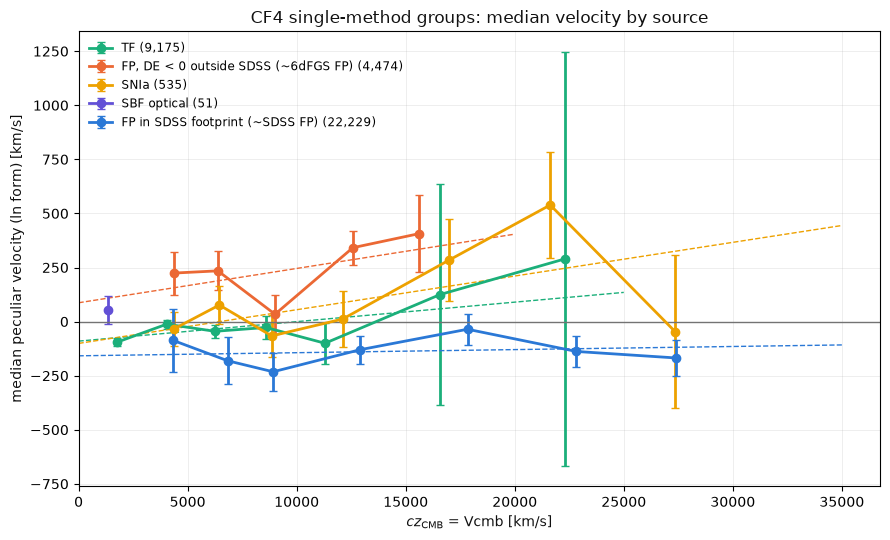

In [32]:
drift = audit.velocity_drift_by_source(sources, config)
fits = audit.zero_point_drift_table(drift)
display(fits.round({"offset": 0, "offset_err": 0, "slope": 4, "slope_err": 4,
                    "modulus_offset": 3, "modulus_offset_err": 3, "chi2": 1}))
shown = drift.source != audit.SOURCE_FP_OTHER
fig = audit.make_source_drift_figure(drift[shown], fits)

**Reading it — a first look, not a verdict.**

- **No source shows a significant zero-point drift.** Every implied modulus offset is within
  ~1.7σ of zero: TF −0.020 ± 0.012, SNIa −0.034 ± 0.020, the 6dF-like FP −0.034 ± 0.027, and the
  SDSS-like FP −0.003 ± 0.010 mag. CF4 calibrated these zero points against each other, so this is
  the expected result. It is also the cheapest way to see an inconsistency, and none shows here.
- **The 6dF-like FP sits high by a constant amount.** Its medians are +220 to +410 km/s in
  four of its five bins (4,000–16,000 km/s; one bin at +34), while the SDSS-like FP sits at −35
  to −230 km/s. The difference is a
  constant offset rather than a slope, and the fit puts it in `a`. A constant offset between the
  southern and northern sky is what a **bulk flow** looks like, since the two patches see the
  flow from opposite sides. It is also what an offset between the 6dF and SDSS FP calibrations
  would look like if it were nearly cz-independent. **This cannot be decided from medians.** It is
  exactly the question Stage 8B answers, by comparing ζ₁ per source on the same density field and,
  where possible, the same sky region.
- Medians of log-distance velocities are themselves biased by the selection (Malmquist). That is
  why the advisor asked for a selection-function correction (roadmap Stage 4) before any
  per-source verdict is made.

## 12 — Addendum against the roadmap

| Roadmap expectation (Stage 1 addendum) | Measured | Verdict |
| --- | --- | --- |
| 2MRS ≈ 43,500 galaxies | 43,526 (Huchra: 43,533) | agrees |
| K_s ≤ 11.75 | `K_tc` ≤ 11.750 in every row; `K_c` exceeds it in 200 | agrees — selection is on `K_tc` |
| |b| ≥ 5°, 8° toward the bulge | 0 violations; min |b| = 5.001° (8.028° in the bulge) | agrees exactly |
| median cz ≈ 8,400 km/s | 8,401 km/s (heliocentric) | agrees |
| 6dFGS FP in the south, SDSS FP in the footprint | 4,489 FP groups at δ < 0 outside SDSS, 22,236 inside | consistent (a sky proxy) |
| CF4 group method counts (roadmap, all / cz < 10k) | FP 27,697 / 3,196; TF 10,187 / 8,919; SNIa 945 / 554 | agrees |
| 96% single-method | 36,693 (96.4%) counting SNII; the roadmap's 36,715 ignored SNII | agrees |

**New, not in the roadmap:** 2MRS has 9-filled sentinel values (`J_c`, `e_J`, `b/a`, `e_V`). 690
bright 2MRS galaxies inside the SDSS footprint are missing from Tempel. With 2MRS as the density
field, CF4 has 2.7× more centers at cz < 10,000. The 6dF-like and SDSS-like FP groups differ by
a constant ~400 km/s in median velocity, with no zero-point *slope* (a bulk flow or a calibration
offset; for Stage 8B).

**Still open for the addendum:** the CF4 individual-galaxy table (EDD) is not in `data/`. Until it
is, the 6dF/SDSS split is the sky proxy above.